# Day 36 — Time Series Fundamentals

## Task-1

The objective is to visualize daily retail sales at three different time scales:
1. Full four-year period
2. Single year
3. Single month

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Load dataset
df = pd.read_csv("retail_sales.csv", parse_dates=["date"])

In [3]:
# Set date as index
df.set_index("date", inplace=True)

In [4]:
# Sort dates
df.sort_index(inplace=True)

In [5]:
# Display dataset information
print("Dataset Shape:", df.shape)

Dataset Shape: (1461, 4)


In [6]:
print("\nFirst 5 Rows:")
display(df.head())


First 5 Rows:


,sales,store_id,promo,temp_c
date,,,,
2021-01-01,1298.13,ST001,1,8.2
2021-01-02,2257.93,ST001,0,5.3
2021-01-03,2116.99,ST001,1,7.8
2021-01-04,1677.36,ST001,0,0.1
2021-01-05,1818.43,ST001,0,11.6


In [7]:
print("\nDataset Information:")
df.info()


Dataset Information:
<class 'pandas.DataFrame'>
DatetimeIndex: 1461 entries, 2021-01-01 to 2024-12-31
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   sales     1455 non-null   float64
 1   store_id  1461 non-null   str    
 2   promo     1461 non-null   int64  
 3   temp_c    1461 non-null   float64
dtypes: float64(2), int64(1), str(1)
memory usage: 64.2 KB


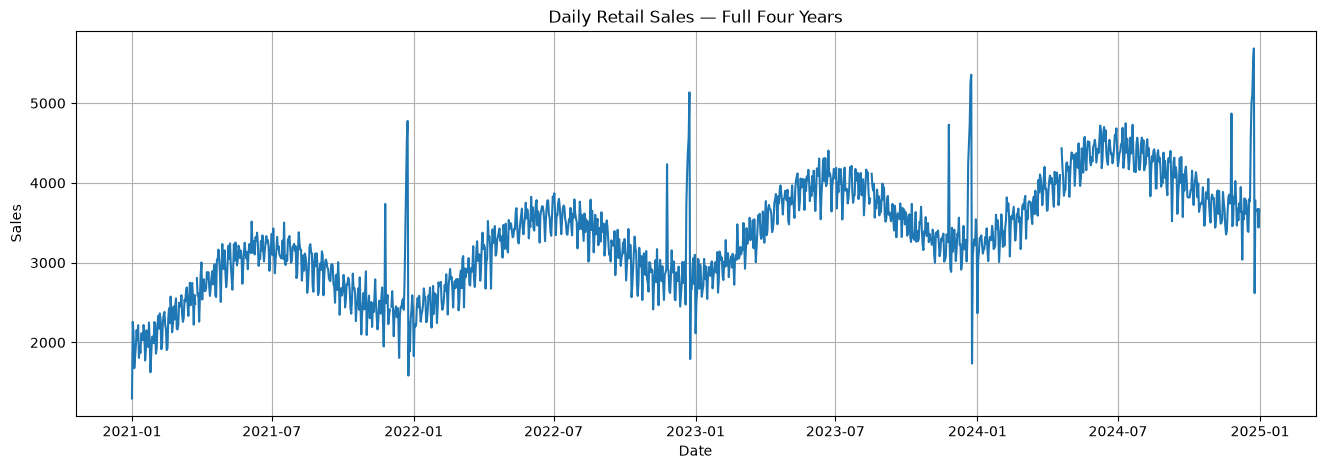

In [8]:
plt.figure(figsize=(16, 5))

plt.plot(df.index, df["sales"])

plt.title("Daily Retail Sales — Full Four Years")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.grid(True)
plt.show()

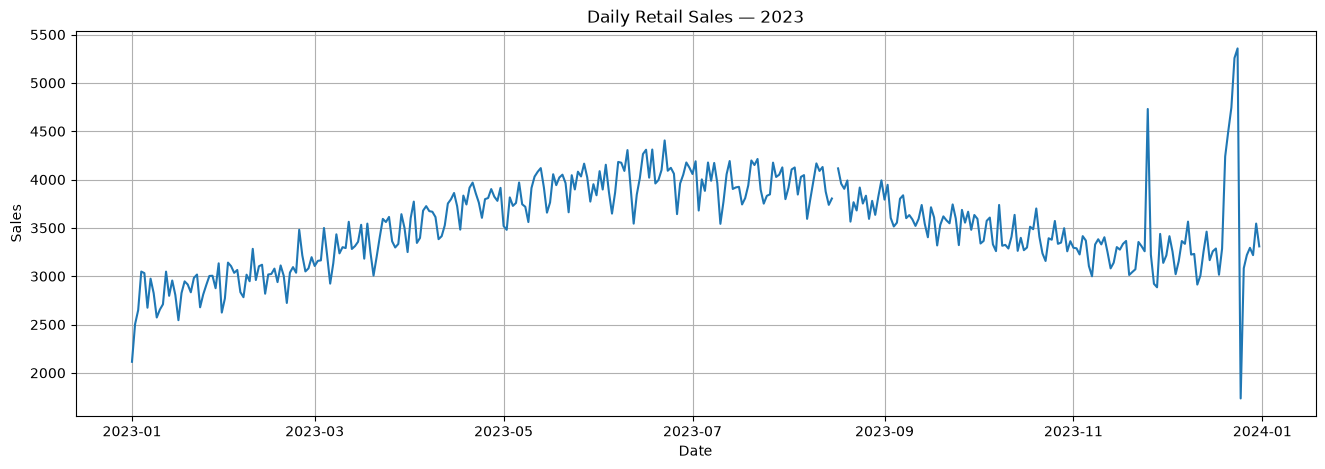

In [9]:
year_data = df.loc["2023"]

plt.figure(figsize=(16, 5))

plt.plot(year_data.index, year_data["sales"])

plt.title("Daily Retail Sales — 2023")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.grid(True)
plt.show()

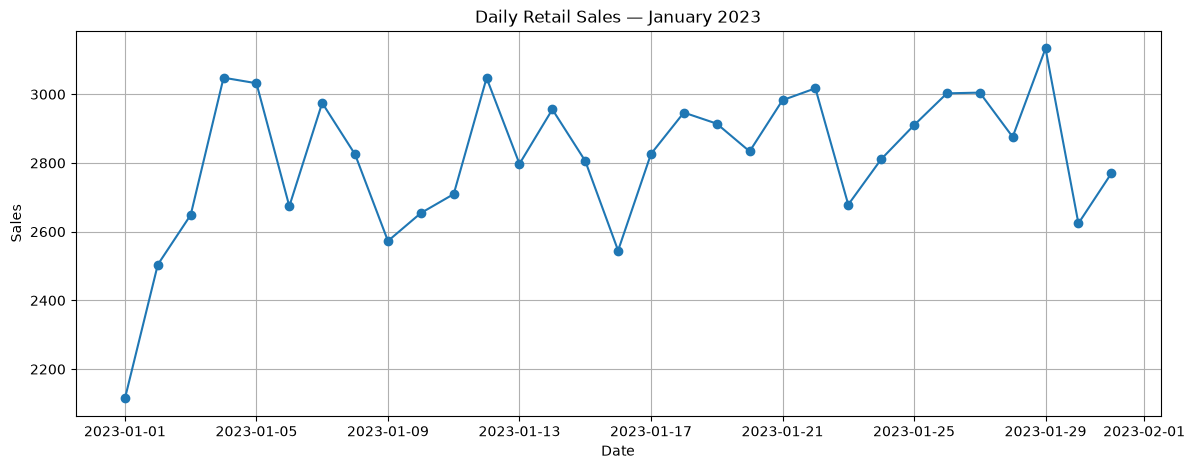

In [10]:
month_data = df.loc["2023-01"]

plt.figure(figsize=(14, 5))

plt.plot(month_data.index, month_data["sales"], marker="o")

plt.title("Daily Retail Sales — January 2023")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.grid(True)
plt.show()

### Conclusion

**Full Four Years:**

The full four-year graph shows an overall increasing trend in retail sales. A yearly seasonal pattern is visible, where sales generally increase during the first half of each year and decrease during the second half.

**Single Year (2023):**

The 2023 graph shows sales increasing from January to approximately June, followed by a gradual decline towards December. Short-term fluctuations are also visible throughout the year.

**Single Month (January 2023):**

The January graph shows daily variations in sales, with values ranging approximately from 2,100 to 3,130. This smaller time scale makes individual daily fluctuations easier to observe.

**Distinct Cycles:**

The dataset contains two main repeating cycles: a weekly cycle of approximately seven days and a yearly cycle of approximately 365 days. The yearly cycle is more visible in the full four-year and single-year graphs, while the weekly pattern can be investigated more closely using shorter time windows.

**Overall Finding:**

Visualizing the data at different time scales helps identify long-term trends, yearly seasonality and short-term daily fluctuations.

## Task-2

The objective is to identify missing sales values and compare three
missing-value treatment methods:

1. Overall Mean Imputation
2. Forward Fill
3. Time-Based Interpolation

In [11]:
# Check missing sales values
missing_dates = df[df["sales"].isnull()].index
print("Total Missing Sales Values:", len(missing_dates))

Total Missing Sales Values: 6


In [12]:
print("\nDates with Missing Sales:")
print(missing_dates)


Dates with Missing Sales:
DatetimeIndex(['2021-03-25', '2021-12-02', '2022-02-04', '2023-08-16',
               '2024-04-18', '2024-12-27'],
              dtype='datetime64[us]', name='date', freq=None)


In [13]:
print("\nMissing Values in Each Column:")
print(df.isnull().sum())


Missing Values in Each Column:
sales       6
store_id    0
promo       0
temp_c      0
dtype: int64


In [14]:
# Original sales series
sales_original = df["sales"].copy()

In [15]:
# Method 1: Overall Mean Imputation
sales_mean = sales_original.fillna(sales_original.mean())

In [16]:
# Method 2: Forward Fill
sales_ffill = sales_original.ffill()

In [17]:
# Method 3: Time-Based Interpolation
sales_interpolated = sales_original.interpolate(method="time")

In [18]:
print("Missing values after filling:")

print("Mean Imputation:", sales_mean.isnull().sum())
print("Forward Fill:", sales_ffill.isnull().sum())
print("Interpolation:", sales_interpolated.isnull().sum())

Missing values after filling:
Mean Imputation: 0
Forward Fill: 0
Interpolation: 0


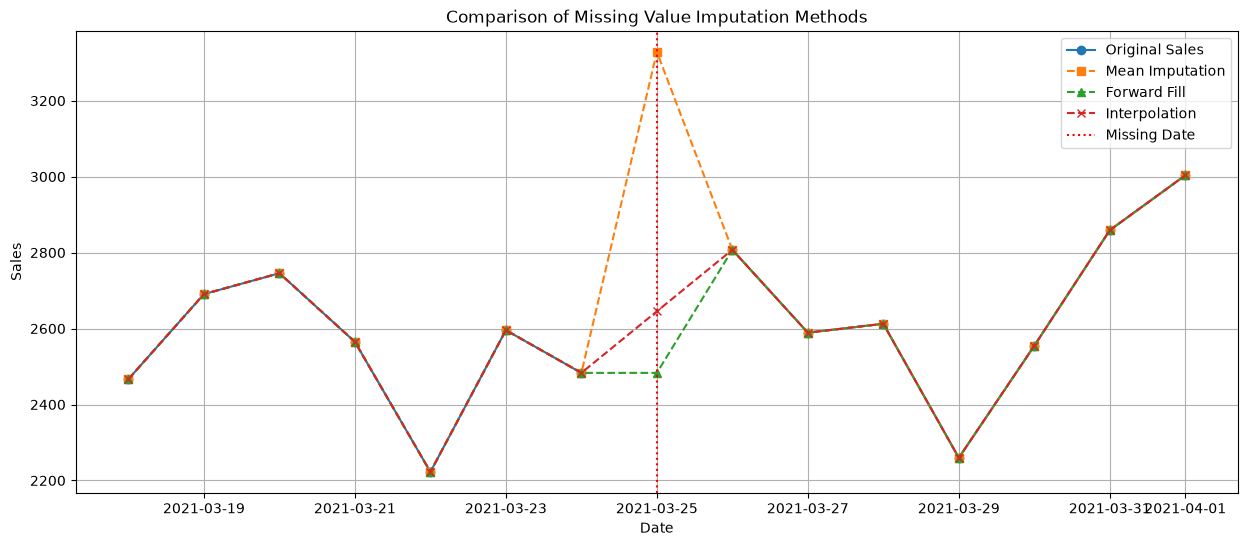

Selected Missing Date: 2021-03-25 00:00:00


In [19]:
# Select the first missing date
gap_date = missing_dates[0]

# Select a two-week window around the gap
start_date = gap_date - pd.Timedelta(days=7)
end_date = gap_date + pd.Timedelta(days=7)

# Extract data for plotting
original_window = sales_original.loc[start_date:end_date]
mean_window = sales_mean.loc[start_date:end_date]
ffill_window = sales_ffill.loc[start_date:end_date]
interpolated_window = sales_interpolated.loc[start_date:end_date]

# Plot comparison
plt.figure(figsize=(15, 6))

plt.plot(original_window.index, original_window,
         marker="o", label="Original Sales")

plt.plot(mean_window.index, mean_window,
         marker="s", linestyle="--", label="Mean Imputation")

plt.plot(ffill_window.index, ffill_window,
         marker="^", linestyle="--", label="Forward Fill")

plt.plot(interpolated_window.index, interpolated_window,
         marker="x", linestyle="--", label="Interpolation")

plt.axvline(gap_date, color="red", linestyle=":",
            label="Missing Date")

plt.title("Comparison of Missing Value Imputation Methods")
plt.xlabel("Date")
plt.ylabel("Sales")

plt.legend()
plt.grid(True)
plt.show()

print("Selected Missing Date:", gap_date)

In [20]:
# Compare statistical measures
comparison = pd.DataFrame({
    "Original": sales_original,
    "Mean Imputation": sales_mean,
    "Forward Fill": sales_ffill,
    "Interpolation": sales_interpolated
})

statistics = comparison.agg(["mean", "std"]).T

statistics.columns = ["Mean Sales", "Standard Deviation"]

print("Statistical Comparison:")
display(statistics.round(2))

Statistical Comparison:


,Mean Sales,Standard Deviation
Original,3328.27,645.58
Mean Imputation,3328.27,644.25
Forward Fill,3327.79,645.82
Interpolation,3328.11,645.87


### Conclusion

**1. Missing Values Identification**

The dataset contains 6 missing values in the sales column. The missing dates are:

- 2021-03-25
- 2021-12-02
- 2022-02-04
- 2023-08-16
- 2024-04-18
- 2024-12-27

The other columns, including store_id, promo and temp_c, do not contain missing values.

**2. Missing Value Treatment**

Three methods were applied:

- Mean Imputation: Replaced missing sales with the overall average.
- Forward Fill: Used the previous available day's sales.
- Time-Based Interpolation: Estimated missing sales using surrounding observations in chronological order.

All three methods successfully filled the six missing values.

**3. Statistical Comparison**

The original sales mean was 3328.27, with a standard deviation of 645.58.

After mean imputation, the mean remained 3328.27 and the standard deviation decreased to 644.25.

After forward fill, the mean became 3327.79 and the standard deviation became 645.82.

After time-based interpolation, the mean became 3328.11 and the standard deviation became 645.87.

**4. Final Conclusion**

Time-based interpolation was selected as the preferred method for handling missing sales values. It considers the chronological order of the data and estimates missing values using neighbouring observations. This makes it more appropriate for this time series than using the overall column average, which ignores the relationship between sales values on nearby dates.

In [21]:
# Create cleaned dataset using time-based interpolation
df["sales"] = df["sales"].interpolate(method="time")

# Verify missing values
print("Missing Sales After Cleaning:", df["sales"].isnull().sum())


Missing Sales After Cleaning: 0


In [22]:
# Display cleaned dataset
display(df.head())

,sales,store_id,promo,temp_c
date,,,,
2021-01-01,1298.13,ST001,1,8.2
2021-01-02,2257.93,ST001,0,5.3
2021-01-03,2116.99,ST001,1,7.8
2021-01-04,1677.36,ST001,0,0.1
2021-01-05,1818.43,ST001,0,11.6


## Task-3

STL (Seasonal and Trend decomposition using Loess) is used to
separate a time series into trend, seasonal and residual components.

In this task, STL decomposition will be performed using:
1. Weekly period = 7 days
2. Yearly period = 365 days

In [23]:
from statsmodels.tsa.seasonal import STL

In [24]:
# Select cleaned sales series
sales = df["sales"]

In [25]:
# Check for missing values
print("Missing Sales Values:", sales.isnull().sum())

Missing Sales Values: 0


In [26]:
# Check date frequency
print("Date Frequency:", pd.infer_freq(df.index))

Date Frequency: D


In [27]:
# Weekly STL decomposition
stl_weekly = STL(sales, period=7, robust=True)

result_weekly = stl_weekly.fit()

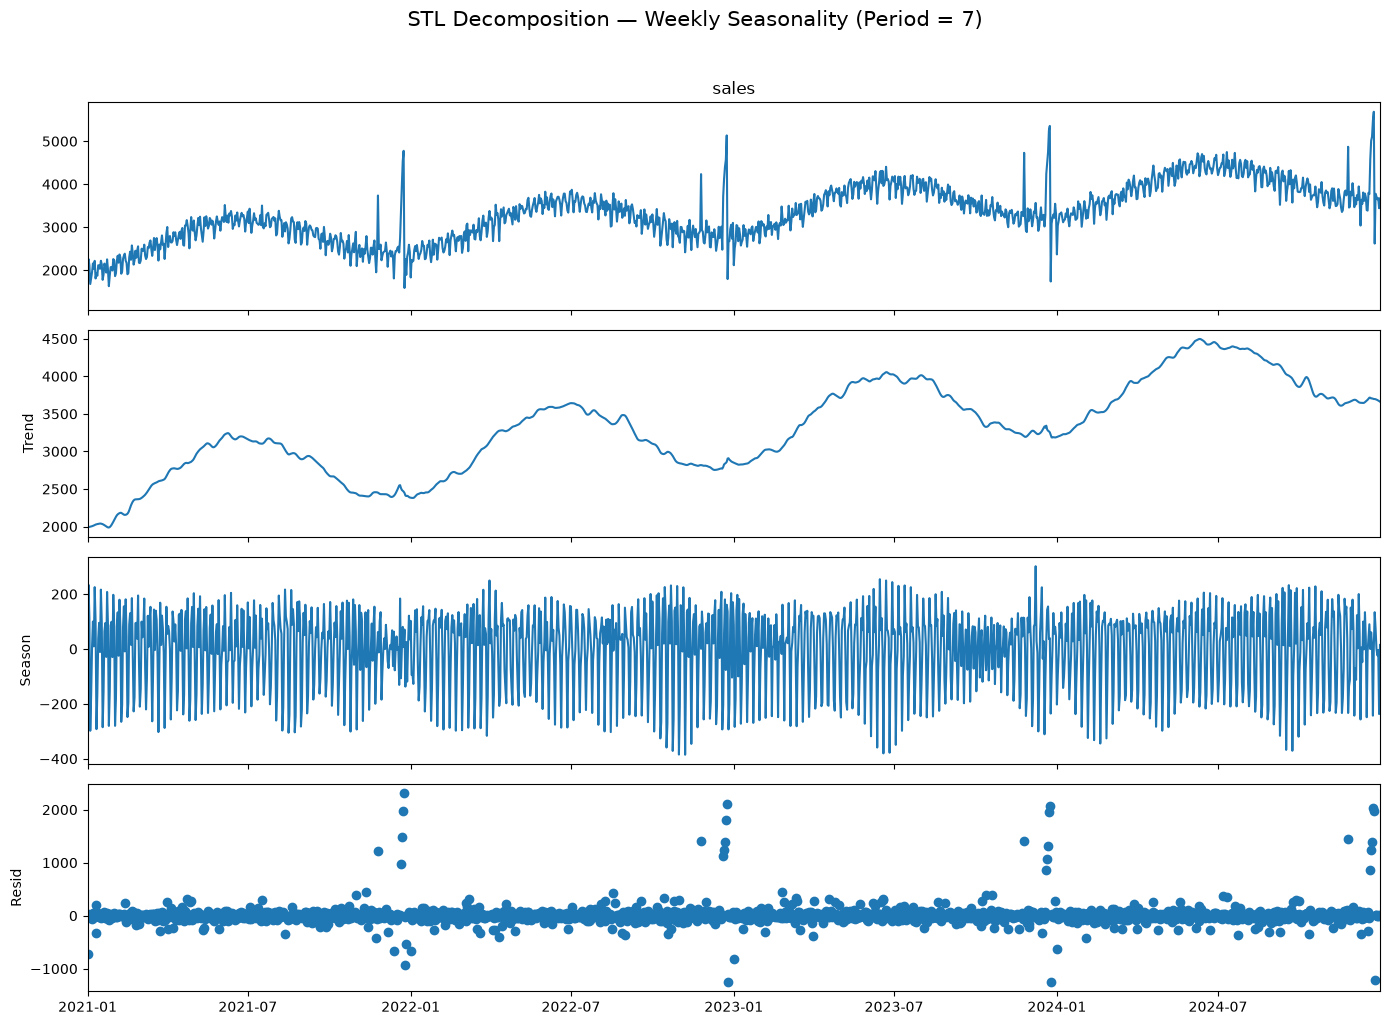

In [28]:
# Plot decomposition
fig = result_weekly.plot()

fig.set_size_inches(14, 10)
fig.suptitle("STL Decomposition — Weekly Seasonality (Period = 7)",
             fontsize=15, y=1.02)

plt.tight_layout()
plt.show()

In [29]:
# Extract weekly components
weekly_components = pd.DataFrame({
    "Trend": result_weekly.trend,
    "Seasonality": result_weekly.seasonal,
    "Residual": result_weekly.resid
})

In [30]:
# Calculate statistics
weekly_stats = pd.DataFrame({
    "Minimum": weekly_components.min(),
    "Maximum": weekly_components.max(),
    "Range": weekly_components.max() - weekly_components.min(),
    "Standard Deviation": weekly_components.std()
})

print("Weekly STL Component Statistics:")
display(weekly_stats.round(2))

Weekly STL Component Statistics:


,Minimum,Maximum,Range,Standard Deviation
Trend,1987.11,4496.94,2509.83,591.91
Seasonality,-385.22,301.60,686.82,138.93
Residual,-1249.72,2305.67,3555.39,230.35


In [31]:
# Calculate variance
total_variance = sales.var()

residual_variance = result_weekly.resid.var()

In [32]:
# Calculate variance explained
variance_explained = (
    1 - (residual_variance / total_variance)
) * 100

print("Total Sales Variance:", round(total_variance, 2))

print("Residual Variance:", round(residual_variance, 2))

print(
    "Variance Explained by Trend and Seasonality:",
    round(variance_explained, 2), "%"
)

Total Sales Variance: 417149.29
Residual Variance: 53060.26
Variance Explained by Trend and Seasonality: 87.28 %


In [33]:
# Yearly STL decomposition
stl_yearly = STL(sales, period=365, robust=True)

result_yearly = stl_yearly.fit()

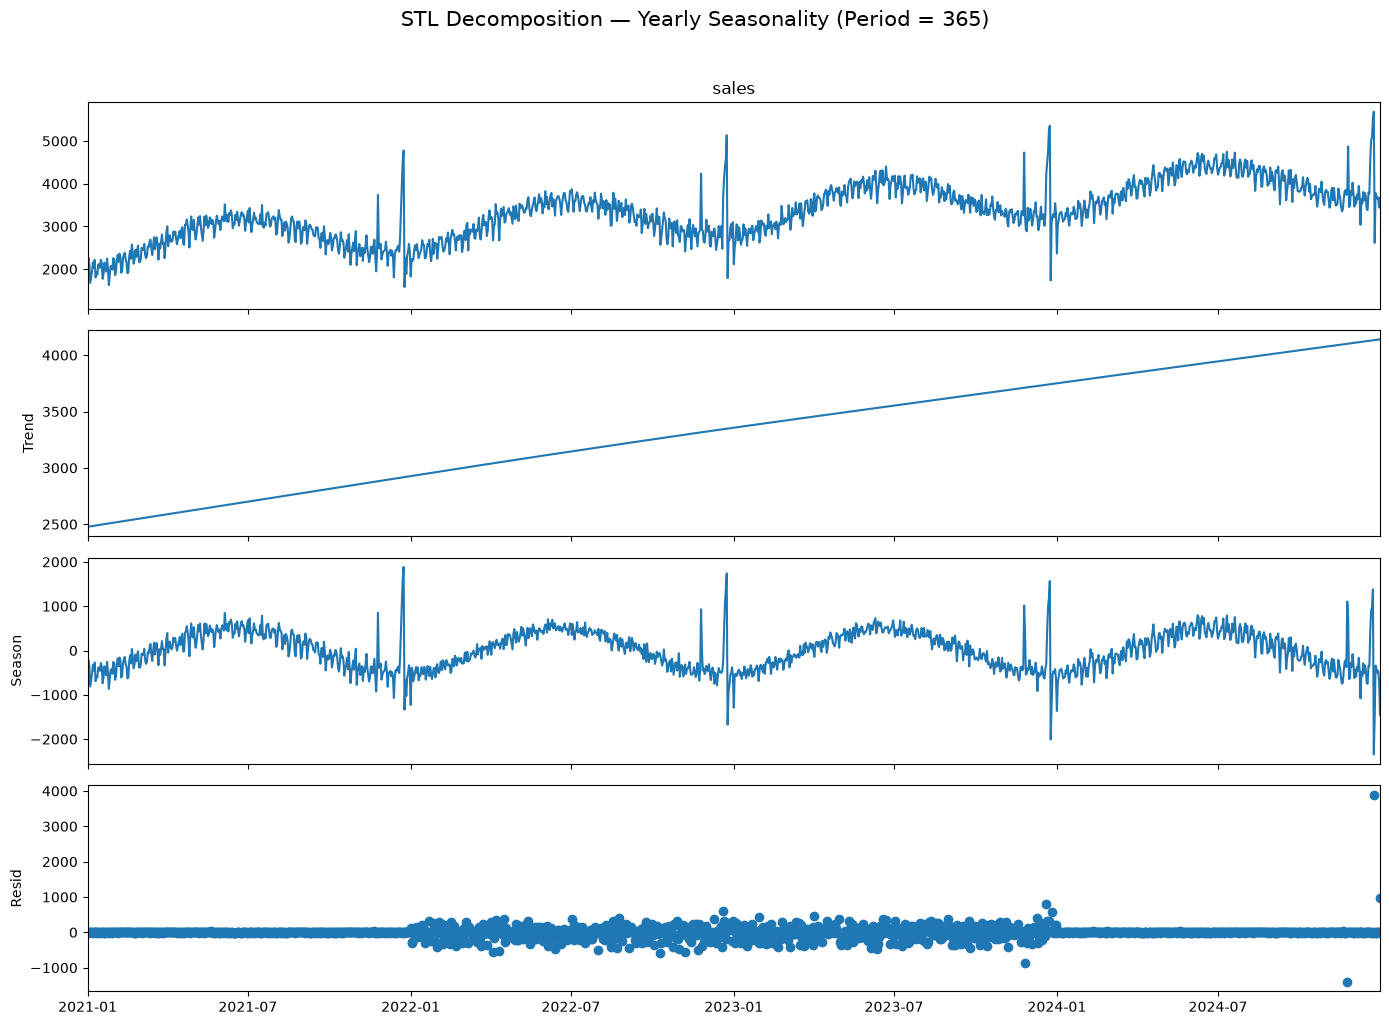

In [34]:
# Plot yearly decomposition
fig = result_yearly.plot()

fig.set_size_inches(14, 10)
fig.suptitle("STL Decomposition — Yearly Seasonality (Period = 365)",
             fontsize=15, y=1.02)

plt.tight_layout()
plt.show()

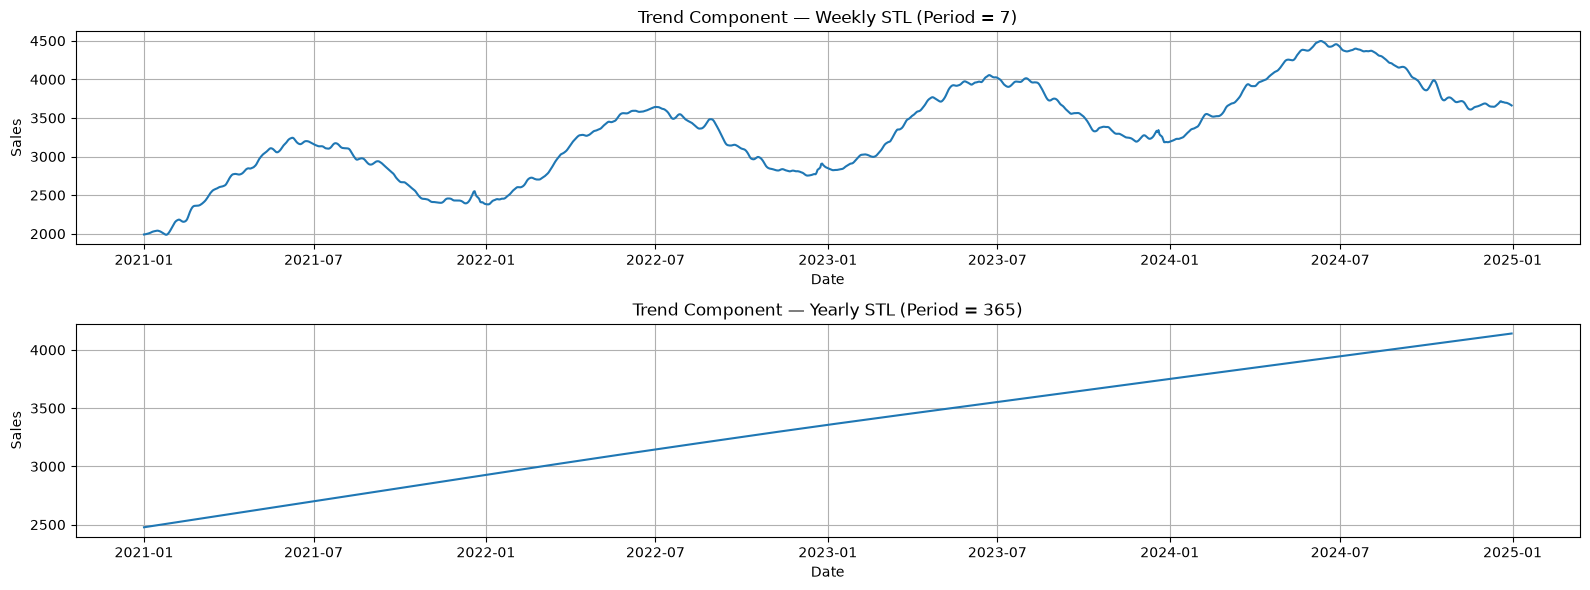

In [35]:
# Compare weekly and yearly trends
plt.figure(figsize=(16, 6))

plt.subplot(2, 1, 1)
plt.plot(result_weekly.trend)
plt.title("Trend Component — Weekly STL (Period = 7)")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True)

plt.subplot(2, 1, 2)
plt.plot(result_yearly.trend)
plt.title("Trend Component — Yearly STL (Period = 365)")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True)

plt.tight_layout()
plt.show()

**1. Weekly STL Decomposition:**

STL decomposition was performed using a period of 7 days to identify weekly seasonality in retail sales. The series was separated into observed, trend, seasonal and residual components.

**2. Component Statistics:**

The minimum, maximum, range and standard deviation were calculated for the trend, seasonal and residual components.

**3. Variance Explained:**

The proportion of variance explained by trend and seasonality was estimated using the residual variance relative to the original sales variance.

**4. Yearly STL Decomposition:**

A second STL decomposition was performed using a period of 365 days to examine the yearly seasonal pattern.

**5. Trend Comparison:**

The weekly and yearly trend components were plotted together for comparison. Changing the seasonal period changes how STL separates trend and seasonality.

**6. Final Conclusion:**

STL does not automatically discover which seasonal cycle should be extracted. The seasonal period must be specified by the user. Using different periods produces different decompositions of the same time series.

## Task-4

The Augmented Dickey-Fuller (ADF) test is used to check
whether a time series is stationary.

The null hypothesis states that the series has a unit root
and is non-stationary.

A p-value below 0.05 provides evidence to reject the
null hypothesis.

In [36]:
from statsmodels.tsa.stattools import adfuller

In [37]:
# Select cleaned sales series
sales = df["sales"]

In [38]:
# Run ADF test
adf_result = adfuller(sales.dropna())

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:", adf_result[4])

if adf_result[1] < 0.05:
    print("Conclusion: The series is stationary.")
else:
    print("Conclusion: The series is non-stationary.")

ADF Statistic: -2.154415799432986
p-value: 0.2232036594673617
Critical Values: {'1%': np.float64(-3.434911997169608), '5%': np.float64(-2.863554810504947), '10%': np.float64(-2.567842671398422)}
Conclusion: The series is non-stationary.


In [39]:
# Apply first differencing
sales_diff = sales.diff()

In [40]:
# Remove missing value
sales_diff = sales_diff.dropna()

In [41]:
# ADF test
adf_first = adfuller(sales_diff)

print("ADF Statistic:", adf_first[0])
print("p-value:", adf_first[1])

if adf_first[1] < 0.05:
    print("Conclusion: First-differenced series is stationary.")
else:
    print("Conclusion: First-differenced series is non-stationary.")

ADF Statistic: -11.625844046198466
p-value: 2.3248072659357523e-21
Conclusion: First-differenced series is stationary.


In [42]:
# Apply seasonal differencing with lag 7
sales_seasonal_diff = sales.diff(7).dropna()

In [43]:
# ADF test
adf_seasonal = adfuller(sales_seasonal_diff)

print("ADF Statistic:", adf_seasonal[0])
print("p-value:", adf_seasonal[1])

if adf_seasonal[1] < 0.05:
    print("Conclusion: Seasonally differenced series is stationary.")
else:
    print("Conclusion: Seasonally differenced series is non-stationary.")

ADF Statistic: -8.502956240244167
p-value: 1.224229772981609e-13
Conclusion: Seasonally differenced series is stationary.


In [44]:
# Extract weekly STL residual
stl_residual = result_weekly.resid.dropna()

In [45]:
# ADF test
adf_residual = adfuller(stl_residual)

print("ADF Statistic:", adf_residual[0])
print("p-value:", adf_residual[1])

if adf_residual[1] < 0.05:
    print("Conclusion: STL residual is stationary.")
else:
    print("Conclusion: STL residual is non-stationary.")

ADF Statistic: -12.65826185020054
p-value: 1.3220916757097405e-23
Conclusion: STL residual is stationary.


In [46]:
# Store ADF results
adf_results = {
    "Raw Sales": adfuller(sales.dropna()),
    "First Differencing": adfuller(sales_diff),
    "Seasonal Differencing (Lag 7)": adfuller(sales_seasonal_diff),
    "STL Residual": adfuller(stl_residual)
}

In [47]:
# Create comparison table
adf_comparison = pd.DataFrame({
    name: {
        "ADF Statistic": result[0],
        "p-value": result[1],
        "Critical Value (5%)": result[4]["5%"],
        "Conclusion": (
            "Stationary" if result[1] < 0.05
            else "Non-stationary"
        )
    }
    for name, result in adf_results.items()
}).T

print("ADF Test Comparison:")
display(adf_comparison.round(4))

ADF Test Comparison:


,ADF Statistic,p-value,Critical Value (5%),Conclusion
Raw Sales,-2.154416,0.223204,-2.863555,Non-stationary
First Differencing,-11.625844,0.0,-2.863555,Stationary
Seasonal Differencing (Lag 7),-8.502956,0.0,-2.863562,Stationary
STL Residual,-12.658262,0.0,-2.863535,Stationary


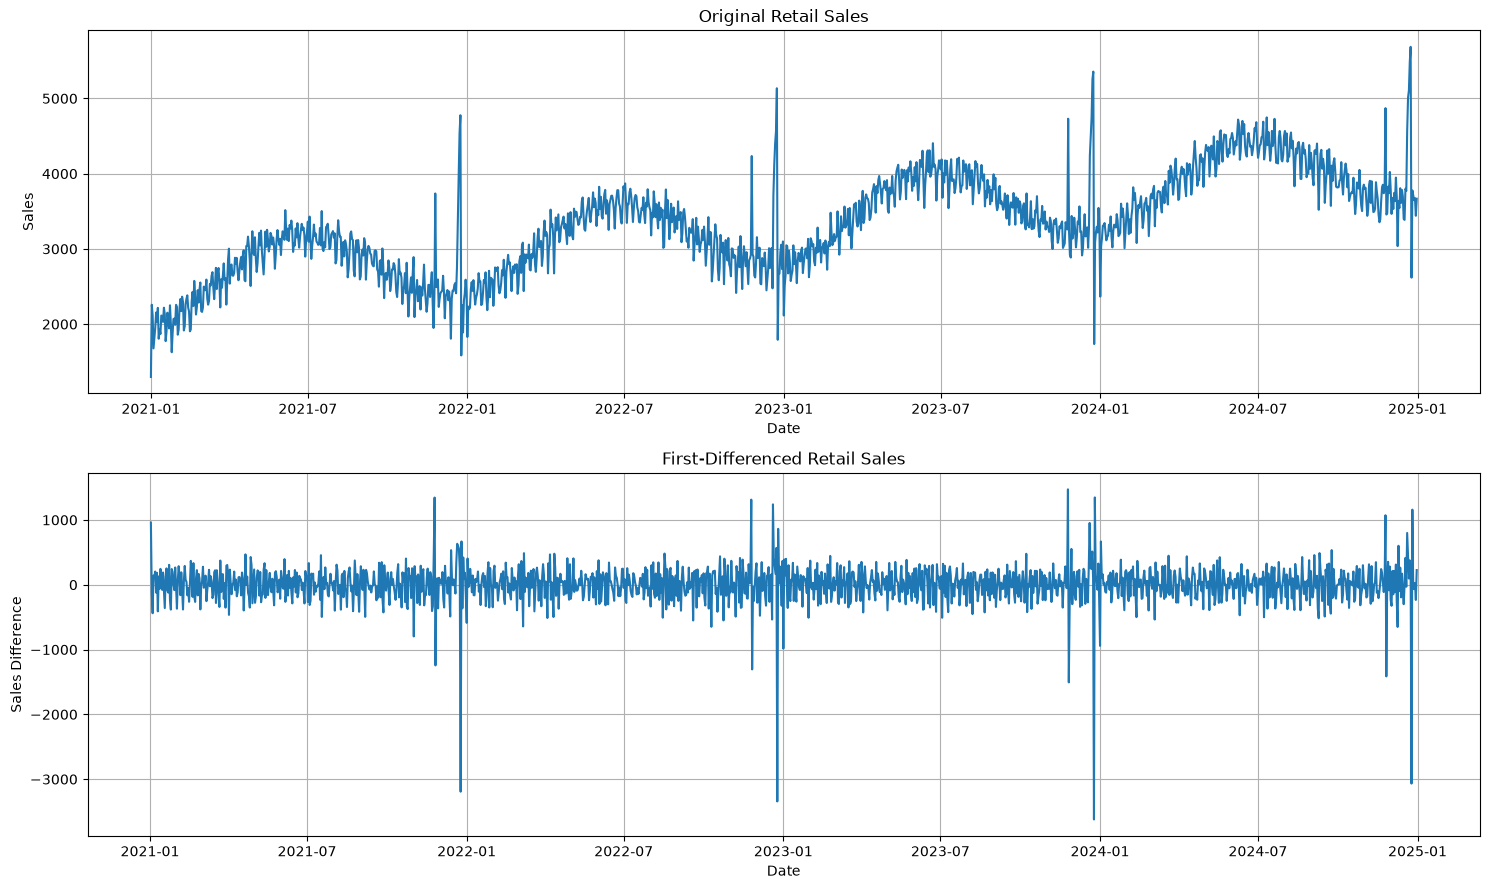

In [48]:
plt.figure(figsize=(15, 9))

# Original sales
plt.subplot(2, 1, 1)
plt.plot(sales)
plt.title("Original Retail Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid(True)

# First-differenced sales
plt.subplot(2, 1, 2)
plt.plot(sales_diff)
plt.title("First-Differenced Retail Sales")
plt.xlabel("Date")
plt.ylabel("Sales Difference")
plt.grid(True)

plt.tight_layout()
plt.show()

**1. Raw Sales ADF Test:**

The ADF test was applied to the original retail sales series. The ADF statistic was -2.1544 and the p-value was 0.2232. Since the p-value was greater than 0.05, the null hypothesis could not be rejected. Therefore, the original sales series was considered non-stationary.

**2. First Differencing:**

First differencing was applied by subtracting the previous day's sales from the current day's sales. The ADF statistic was -11.6258 and the p-value was approximately 2.32e-21. Since the p-value was below 0.05, the null hypothesis was rejected, indicating stationarity.

**3. Seasonal Differencing:**

Seasonal differencing with a lag of 7 was performed to compare sales with the same weekday from the previous week. The ADF statistic was -8.5030 and the p-value was approximately 1.22e-13. The result indicated that the seasonally differenced series was stationary.

**4. STL Residual:**

The ADF test was performed on the residual component obtained from weekly STL decomposition. The ADF statistic was -12.6583 and the p-value was approximately 1.32e-23. This indicated that the STL residual was stationary.

**5. ADF Test Interpretation:**

The ADF test uses a null hypothesis that the series contains a unit root and is non-stationary. Therefore, a p-value below 0.05 provides evidence to reject the null hypothesis, which is the opposite direction of many common statistical tests.

**6. Final Conclusion:**

The original retail sales series was non-stationary because of its underlying trend and seasonal patterns. First differencing, seasonal differencing with lag 7, and STL decomposition produced stationary series according to the ADF test. These transformations help prepare time series data for further analysis and forecasting.

## Task-5 

ACF (Autocorrelation Function) measures the correlation between
a time series and its lagged values.

PACF (Partial Autocorrelation Function) measures the direct
correlation at a particular lag after accounting for shorter lags.

In this task, we will compare raw sales and differenced sales.

In [ ]:
from statsmodels.tsa.stattools import acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [50]:
# Calculate ACF for raw sales
raw_acf = acf(sales, nlags=30)

<Figure size 1300x500 with 0 Axes>

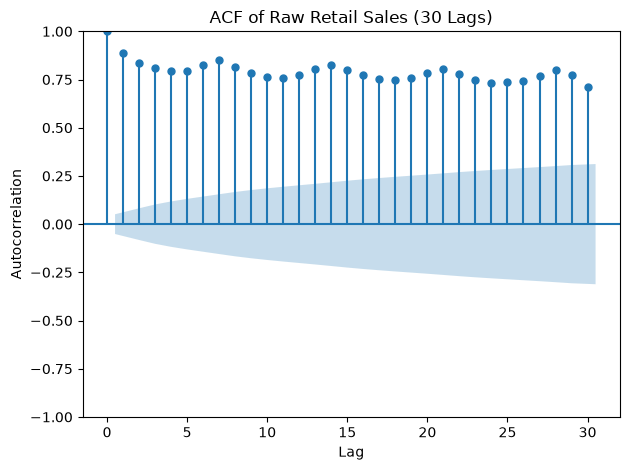

In [51]:
# Plot ACF
plt.figure(figsize=(13, 5))

plot_acf(sales, lags=30)

plt.title("ACF of Raw Retail Sales (30 Lags)")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")

plt.tight_layout()
plt.show()

In [52]:
# Print autocorrelation values from lag 1 to 14
print("ACF Values of Raw Sales:")

for lag in range(1, 15):
    print(f"Lag {lag}: {raw_acf[lag]:.4f}")

ACF Values of Raw Sales:
Lag 1: 0.8851
Lag 2: 0.8347
Lag 3: 0.8115
Lag 4: 0.7932
Lag 5: 0.7921
Lag 6: 0.8247
Lag 7: 0.8508
Lag 8: 0.8126
Lag 9: 0.7816
Lag 10: 0.7640
Lag 11: 0.7587
Lag 12: 0.7728
Lag 13: 0.8029
Lag 14: 0.8243


In [53]:
# Count lags with autocorrelation above 0.5
count_high_acf = np.sum(raw_acf[1:] > 0.5)

print("Number of lags with ACF above 0.5:", count_high_acf)

Number of lags with ACF above 0.5: 30


In [54]:
# First differencing
sales_diff = sales.diff().dropna()

print("Original Series Length:", len(sales))
print("Differenced Series Length:", len(sales_diff))

Original Series Length: 1461
Differenced Series Length: 1460


In [55]:
# Calculate ACF for differenced sales
diff_acf = acf(sales_diff, nlags=30)

<Figure size 1300x500 with 0 Axes>

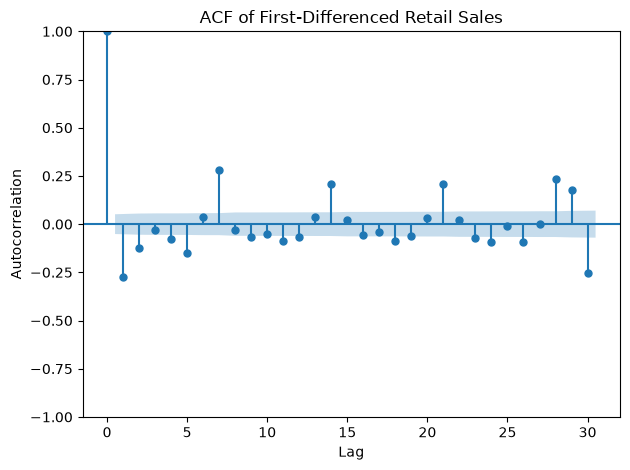

In [56]:
# Plot ACF
plt.figure(figsize=(13, 5))

plot_acf(sales_diff, lags=30)

plt.title("ACF of First-Differenced Retail Sales")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")

plt.tight_layout()
plt.show()

In [57]:
# Compare lag-7 autocorrelation
raw_lag7 = raw_acf[7]
diff_lag7 = diff_acf[7]

print("Lag-7 Autocorrelation Comparison")

print("Before Differencing:", round(raw_lag7, 4))
print("After Differencing:", round(diff_lag7, 4))

Lag-7 Autocorrelation Comparison
Before Differencing: 0.8508
After Differencing: 0.279


<Figure size 1300x500 with 0 Axes>

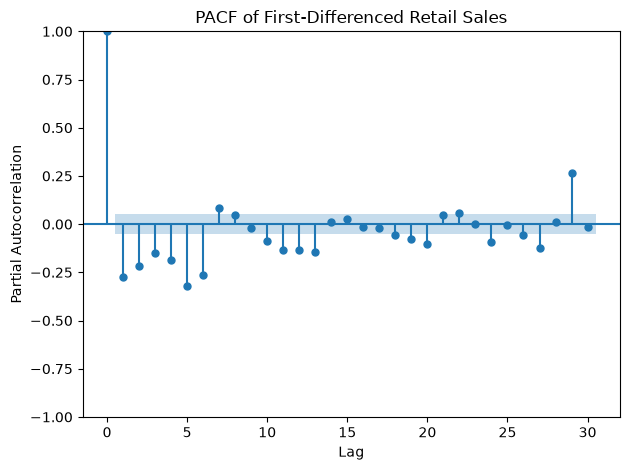

In [58]:
# Plot PACF of differenced sales
plt.figure(figsize=(13, 5))

plot_pacf(sales_diff, lags=30, method="ywm")

plt.title("PACF of First-Differenced Retail Sales")
plt.xlabel("Lag")
plt.ylabel("Partial Autocorrelation")

plt.tight_layout()
plt.show()

**1. ACF of Raw Sales:**

The ACF of the original sales series was plotted using 30 lags. The autocorrelation values from lag 1 to lag 14 were calculated. All 30 non-zero lags had autocorrelation values above 0.5, indicating strong autocorrelation across multiple lags.

**2. Reason for High Autocorrelation:**

The raw sales series showed high autocorrelation because it contained a long-term increasing trend and seasonal patterns. The trend caused current and previous sales observations to move together, resulting in high autocorrelation at nearly every lag.

**3. ACF After Differencing:**

First differencing was applied to reduce the influence of the long-term trend. The ACF of the differenced series showed considerably lower autocorrelation values compared with the original series.

**4. Lag-7 Comparison:**

The lag-7 autocorrelation decreased from 0.8508 before differencing to 0.2790 after differencing. This indicates that the weekly autocorrelation became much weaker after removing the trend, although a weekly relationship remained.

**5. PACF Analysis:**

The PACF of the differenced series showed significant negative relationships at several early lags and a positive relationship at lag 7. These results help identify candidate historical sales features for forecasting.

**6. ACF and PACF Difference:**

ACF measures the overall correlation between a time series and its lagged values, including indirect relationships. PACF measures the direct correlation at a particular lag after accounting for shorter lags.

**7. Final Conclusion:**

The raw ACF was high across nearly every lag because the original sales series was non-stationary and contained a strong trend. Differencing reduced this effect and made the autocorrelation structure easier to understand. PACF was used to identify potential lag features for the forecasting model.

# Task-6

In [59]:
data = df.copy()
data["sales"] = data["sales"].interpolate()

# lag features -- chosen with the PACF in mind
for lag in [1, 2, 7, 14, 28]:
    data[f"lag_{lag}"] = data["sales"].shift(lag)

# rolling features -- note the shift(1) BEFORE rolling
data["roll7"]  = data["sales"].shift(1).rolling(7).mean()
data["roll28"] = data["sales"].shift(1).rolling(28).mean()

# calendar features come free with a datetime index
data["dayofweek"] = data.index.dayofweek
data["month"]     = data.index.month
data["dayofyear"] = data.index.dayofyear

data = data.dropna()

print(f"{len(data)} rows remain after creating lags (we lost the first 28 days)")

1433 rows remain after creating lags (we lost the first 28 days)


In [60]:
data["roll7"] = data["sales"].shift(1).rolling(7).mean()

In [61]:
# demonstrate the leak concretely
check = pd.DataFrame({
    "sales": data["sales"].head(10),
    "WRONG_roll7": data["sales"].rolling(7).mean().head(10),
    "correct_roll7": data["sales"].shift(1).rolling(7).mean().head(10),
})

print(check.round(0).to_string())

print("\nthe WRONG column uses today's sales to predict today's sales")

             sales  WRONG_roll7  correct_roll7
date                                          
2021-01-29  1991.0          NaN            NaN
2021-01-30  2257.0          NaN            NaN
2021-01-31  2229.0          NaN            NaN
2021-02-01  1860.0          NaN            NaN
2021-02-02  1925.0          NaN            NaN
2021-02-03  2211.0          NaN            NaN
2021-02-04  2334.0       2115.0            NaN
2021-02-05  2173.0       2141.0         2115.0
2021-02-06  2364.0       2157.0         2141.0
2021-02-07  2298.0       2166.0         2157.0

the WRONG column uses today's sales to predict today's sales


### Task 06 — Lag and Rolling Features

Created lag features using previous sales observations at 1, 2, 7, 14, and 28 days. Also created 7-day and 28-day rolling mean features using historical sales data.

Added calendar features including day of the week, month, and day of the year. The rolling features were shifted before calculating the averages to prevent data leakage.

After creating the features and removing missing rows, 1433 rows remained, with the first 28 days lost because sufficient historical observations were not available.

A leakage demonstration was performed by comparing rolling averages with and without shifting. The unshifted rolling average includes today's sales, which causes data leakage. Python does not generate an error for this mistake because it is a logical issue rather than a syntax error.

**Conclusion:** Historical lag features, rolling averages, and calendar features were successfully created for time-series forecasting without using future information.

# Task-7

In [62]:
from sklearn.metrics import mean_absolute_error

HORIZON = 28

train = data.iloc[:-HORIZON]
test = data.iloc[-HORIZON:]

y_train = train["sales"]
y_test = test["sales"]

print("Training rows:", len(train))
print("Testing rows:", len(test))
print("Test period:", test.index.min().date(), "to", test.index.max().date())

Training rows: 1405
Testing rows: 28
Test period: 2024-12-04 to 2024-12-31


In [63]:
# Baseline 1: Predict the training mean for every test day
pred_mean = pd.Series(y_train.mean(), index=test.index)

In [64]:
# Baseline 2: Predict yesterday's sales
pred_yesterday = pd.Series(y_train.iloc[-1], index=test.index)

In [65]:
# Baseline 3: Predict sales from the same day last week
pred_last_week = data["sales"].shift(7).loc[test.index]

In [66]:
# Calculate MAE
mae_mean = mean_absolute_error(y_test, pred_mean)
mae_yesterday = mean_absolute_error(y_test, pred_yesterday)
mae_last_week = mean_absolute_error(y_test, pred_last_week)

baseline_results = pd.DataFrame({
    "Baseline": ["Training Mean", "Yesterday", "Same Day Last Week"],
    "MAE": [mae_mean, mae_yesterday, mae_last_week]
})

print(baseline_results.sort_values("MAE").to_string(index=False))

          Baseline        MAE
         Yesterday 407.031607
     Training Mean 601.495346
Same Day Last Week 676.767321


In [67]:
feature_cols = [
    "lag_1",
    "lag_2",
    "lag_7",
    "lag_14",
    "lag_28",
    "roll7",
    "roll28",
    "dayofweek",
    "month",
    "dayofyear"
]

X = data[feature_cols]
y = data["sales"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (1433, 10)
Target shape: (1433,)


In [68]:
# Keep the last 28 days for testing
train = data.iloc[:-28]
test = data.iloc[-28:]

X_train = train[feature_cols]
y_train = train["sales"]

X_test = test[feature_cols]
y_test = test["sales"]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Test period:", test.index.min().date(), "to", test.index.max().date())

Training rows: 1405
Testing rows: 28
Test period: 2024-12-04 to 2024-12-31


# Task-8

In [69]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

In [70]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_predictions)

print(f"Random Forest MAE: {rf_mae:.2f}")

Random Forest MAE: 381.91


Feature Importance:
lag_1        0.3995
roll7        0.2183
lag_7        0.1919
lag_14       0.0870
roll28       0.0423
dayofyear    0.0337
lag_28       0.0101
lag_2        0.0092
dayofweek    0.0057
month        0.0023
dtype: float64


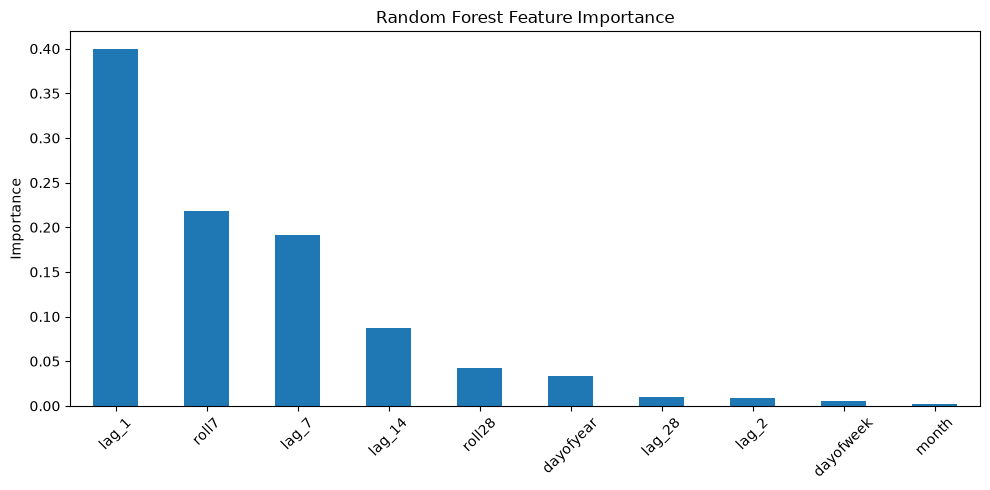

In [71]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=feature_cols
).sort_values(ascending=False)

print("Feature Importance:")
print(importance.round(4))

importance.plot(
    kind="bar",
    figsize=(10, 5),
    title="Random Forest Feature Importance"
)

plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [72]:
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score

rf_cv = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

# Random K-Fold
kf = KFold(n_splits=5, shuffle=True, random_state=42)

kf_scores = cross_val_score(
    rf_cv, X, y,
    cv=kf,
    scoring="neg_mean_absolute_error"
)

# Time Series Split
tscv = TimeSeriesSplit(n_splits=5)

ts_scores = cross_val_score(
    rf_cv, X, y,
    cv=tscv,
    scoring="neg_mean_absolute_error"
)

print("Random K-Fold MAE:", -kf_scores.mean())
print("Time Series Split MAE:", -ts_scores.mean())

Random K-Fold MAE: 138.95436722320463
Time Series Split MAE: 186.04276454633717


# Task-9

In [73]:
promo_sales = df.groupby("promo")["sales"].mean()

print("Average Sales by Promo:")
print(promo_sales)

print("\nDifference in Average Sales:")
print(promo_sales.loc[1] - promo_sales.loc[0])

Average Sales by Promo:
promo
0    3330.594184
1    3314.408661
Name: sales, dtype: float64

Difference in Average Sales:
-16.18552279420237


In [74]:
temp_corr = df[["sales", "temp_c"]].corr()

print("Correlation between Sales and Temperature:")
print(temp_corr)

print("\nSales-Temperature Correlation:")
print(temp_corr.loc["sales", "temp_c"])

Correlation between Sales and Temperature:
           sales    temp_c
sales   1.000000  0.490846
temp_c  0.490846  1.000000

Sales-Temperature Correlation:
0.49084603003707955


In [75]:
print(type(stl_weekly))

<class 'statsmodels.tsa.stl._stl.STL'>


In [76]:
stl_weekly_result = stl_weekly.fit()

In [77]:
seasonal_data = pd.DataFrame({
    "sales_residual": stl_weekly_result.resid,
    "temp_c": df["temp_c"]
}).dropna()

residual_corr = seasonal_data["sales_residual"].corr(
    seasonal_data["temp_c"]
)

print("Correlation after removing trend and weekly seasonality:")
print(residual_corr)

Correlation after removing trend and weekly seasonality:
-0.06199929571871935


# Day 36 — Time Series Fundamentals
## Final Forecasting Brief

### 1. Project Overview
The objective of this project was to analyze daily retail sales data, understand its time-series patterns, perform stationarity testing, create historical features, and evaluate forecasting models.

The dataset contains 1,461 daily observations covering January 2021 to December 2024, with sales, promotion status, and temperature information.

### 2. Data Analysis and Preprocessing
The dataset contained six missing sales values. Three methods were compared: mean imputation, forward fill, and linear interpolation.

| Method | Mean | Standard Deviation |
|---|---:|---:|
| Original available sales | 3328.27 | 645.58 |
| Mean imputation | 3328.27 | 644.25 |
| Forward fill | 3327.79 | 645.82 |
| Linear interpolation | 3328.11 | 645.87 |

Linear interpolation was selected because it estimates missing values using neighboring observations and preserves the chronological nature of the data.

### 3. Trend and Seasonality Analysis
STL decomposition was used to separate the sales series into trend, seasonal, and residual components.

The weekly decomposition showed:
- Trend standard deviation: 591.91
- Seasonal standard deviation: 138.93
- Residual standard deviation: 230.35
- Variance explained by trend and seasonality: 87.28%

This indicates that trend and weekly seasonal patterns explain a substantial portion of sales variation.

### 4. Stationarity Testing
The Augmented Dickey-Fuller (ADF) test was applied to different versions of the sales series.

| Series | ADF p-value | Result |
|---|---:|---|
| Original sales | 0.2232 | Non-stationary |
| First difference | 2.32 × 10⁻²¹ | Stationary |
| Seasonal difference (lag 7) | 1.22 × 10⁻¹³ | Stationary |
| STL residual | 1.32 × 10⁻²³ | Stationary |

The original sales series was non-stationary. Differencing and STL decomposition helped produce stationary series.

### 5. ACF and PACF Analysis
The original sales series showed strong autocorrelation, with 30 out of 30 examined lags having correlation above 0.5.

After first differencing, the lag-7 autocorrelation decreased from 0.8508 to 0.279. This suggests that differencing reduced the influence of trend and made the remaining autocorrelation structure easier to examine.

### 6. Feature Engineering
Historical and calendar-based features were created:
- Lag features: 1, 2, 7, 14, and 28 days.
- Rolling averages: 7-day and 28-day windows.
- Calendar features: day of week, month, and day of year.

A one-day shift was applied before calculating rolling averages to prevent using the current day's sales as an input for predicting that same day's sales.

The final feature dataset contained 1,433 rows and 10 input features.

### 7. Forecasting Model Evaluation
The final 28 days were kept as the test set, while earlier observations were used for training.

| Model | MAE |
|---|---:|
| Yesterday baseline | 407.03 |
| Training Mean baseline | 601.50 |
| Same Day Last Week baseline | 676.77 |
| Random Forest Regressor | 381.91 |

Random Forest achieved the lowest test MAE of 381.91, improving on the best baseline (Yesterday) by approximately 6.2%.

The most important features were:
- lag_1: 0.3995
- roll7: 0.2183
- lag_7: 0.1919
- lag_14: 0.0870

Recent historical sales were more influential than calendar features.

### 8. Cross-Validation Comparison

| Validation Method | Average MAE |
|---|---:|
| Random K-Fold | 138.95 |
| Time Series Split | 186.04 |

Time Series Split is more suitable for forecasting because it respects chronological order. Random K-Fold can give overly optimistic results because future observations may appear in training folds while earlier observations are being validated.

### 9. External Drivers Analysis
**Promotional activity:**
- Average sales without promotion: 3330.59
- Average sales with promotion: 3314.41
- Difference: -16.19

Promotional days had slightly lower average sales in this dataset. This comparison alone does not establish whether promotions affect sales.

**Temperature:**
- Original sales-temperature correlation: +0.4908
- Residual sales-temperature correlation: -0.0620

After removing trend and weekly seasonality, the relationship between temperature and residual sales became very weak.

### 10. Final Conclusion and Recommendations
The analysis identified substantial trend and seasonal patterns in daily retail sales. Differencing improved stationarity, while lag and rolling features helped capture historical sales behavior.

The Random Forest model achieved a test MAE of 381.91 and performed better than the evaluated baseline models. Time Series Split provided a more realistic validation approach than random K-Fold.

**Recommendations:**
1. Use chronological validation for future forecasting experiments.
2. Monitor recent sales patterns using lag and rolling features.
3. Evaluate model performance on additional future periods.
4. Investigate promotional effectiveness using more detailed statistical analysis.
5. Consider additional forecasting models and compare their performance before deployment.

**Overall Result:** The project successfully covered time-series visualization, missing-value treatment, decomposition, stationarity testing, feature engineering, forecasting, model evaluation, and external driver analysis.